# Link al proyecto en Google Colab📌​

[![Abrir en Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/drive/10ybtOhXt7YEPw3KWzXKhGNupV2ts3W9h?usp=drive_link)

### 📥 Descarga Automática del Dataset
Ejecuta esta celda para descargar el archivo directamente desde un repositorio público cada vez que se reinicie el entorno de Colab. Esto evitará que tengas que subir el archivo manualmente.

In [34]:
import kagglehub
from kagglehub import KaggleDatasetAdapter

# Set the path to the file you'd like to load
file_path = "WA_Fn-UseC_-Telco-Customer-Churn.csv"

# Load the latest version
df = kagglehub.load_dataset(
  KaggleDatasetAdapter.PANDAS,
  "blastchar/telco-customer-churn",
  file_path,
  # Provide any additional arguments like
  # sql_query or pandas_kwargs. See the
  # documenation for more information:
  # https://github.com/Kaggle/kagglehub/blob/main/README.md#kaggledatasetadapterpandas
)

print("First 5 records:", df.head())

C:\Users\Usuario\AppData\Local\Temp\ipykernel_10456\1676996981.py:8: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  df = kagglehub.load_dataset(


First 5 records:    customerID  gender  SeniorCitizen Partner Dependents  tenure PhoneService  \
0  7590-VHVEG  Female              0     Yes         No       1           No   
1  5575-GNVDE    Male              0      No         No      34          Yes   
2  3668-QPYBK    Male              0      No         No       2          Yes   
3  7795-CFOCW    Male              0      No         No      45           No   
4  9237-HQITU  Female              0      No         No       2          Yes   

      MultipleLines InternetService OnlineSecurity  ... DeviceProtection  \
0  No phone service             DSL             No  ...               No   
1                No             DSL            Yes  ...              Yes   
2                No             DSL            Yes  ...               No   
3  No phone service             DSL            Yes  ...              Yes   
4                No     Fiber optic             No  ...               No   

  TechSupport StreamingTV StreamingMovies    

# ​🅰️​Fundamentos, Ingesta y Limpieza de Datos 

## Problema de negocio
Una empresa de telecomunicaciones pierde clientes que cancelan su suscripción (churn). Quieren predecir el comportamiento de dichos clientes para poder retenerlos, por lo que se debe determinar qué características se asocian con la cancelación del servicio. A partir de ahí, se puede anticipar qué clientes están en riesgo e implementar medidas preventivas.  


In [35]:
# Importaciones
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, LabelEncoder
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

sns.set_theme(style="whitegrid")

## Planteo de hipótesis e identificación de variable objetivo

In [36]:
df.shape

(7043, 21)

In [37]:
df.head(25)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
5,9305-CDSKC,Female,0,No,No,8,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes
6,1452-KIOVK,Male,0,No,Yes,22,Yes,Yes,Fiber optic,No,...,No,No,Yes,No,Month-to-month,Yes,Credit card (automatic),89.10,1949.4,No
7,6713-OKOMC,Female,0,No,No,10,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,No,Mailed check,29.75,301.9,No
8,7892-POOKP,Female,0,Yes,No,28,Yes,Yes,Fiber optic,No,...,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes
9,6388-TABGU,Male,0,No,Yes,62,Yes,No,DSL,Yes,...,No,No,No,No,One year,No,Bank transfer (automatic),56.15,3487.95,No


In [38]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [39]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

## Hipótesis analíticas

### H1
Los clientes con contrato mes a mes cancelan más que los de contratos de 1 o 2 años. El contrato mes a mes no tiene penalidad por cancelar, así que irse es más fácil. Los anuales y bienales son decisiones a largo plazo, que conllevan un nivel de ponderación distinta a la hora de rescindir el contrato.

### H2
A menor antigüedad (`tenure`), mayor probabilidad de cancelar la suscripción. Los primeros meses son clave, ya que un cliente nuevo no está acostumbrado al servicio, ni siente necesariamente que le deba fidelidad alguna. 

### H3
Los clientes con cargos mensuales altos cancelan más. A mayor precio, más pesa la decisión de seguir pagando.

### H4
Quienes pagan con cheque electrónico cancelan más que quienes tienen débito automático. Es distinto cómo se procesa el gasto consciente, que el gasto automatizado. Con el pago manual, el cliente tiene que autorizar el pago cada vez, así que la decisión de seguir con el servicio se repite constantemente. Con el débito automático, el pago ocurre sin que intervenga y la cancelación requiere una acción deliberada.

## Variable objetivo: `Churn`.
Es categórica nominal binaria (Yes/No) e indica si el cliente canceló el servicio.

## Clasificación del Dataset y Variables
El dataset es de tipo estructurado, se presenta en formato CSV.
### Clasificación teórica de las variables
- **Cualitativas nominales:** `customerID` (identificador único), `gender`, `SeniorCitizen`, `Partner`, `Dependents`, `PhoneService`, `MultipleLines`, `InternetService`, `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies`, `PaperlessBilling`, `PaymentMethod` y `Churn`

- **Cualitativas ordinales:** `Contract`

- **Cuantitativas discretas:** `tenure`

- **Cuantitativas continuas:** `MonthlyCharges`, `TotalCharges`

In [40]:
df.dtypes

customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object

`SeniorCitizen`: pandas la lee como **int64**, pero es cualitativa nominal (0/1 = no/sí).
`TotalCharges`: pandas la lee como **texto**, pero es cuantitativa continua, porque tiene cadenas " ".
`Contract`: pandas la lee como **texto** y no refleja el orden de una variable ordinal.
`customerID`: **texto**, coincide con su clasificación, pero es un identificador.
El resto coincide: las Yes/No como **texto**, `tenure` como entero (discreta) y `MonthlyCharges` como **float64** (continua).

## Limpieza y Calidad de Datos
Se trabaja sobre una copia (`df_clean`) para conservar el dataset original.

In [41]:
df_clean = df.copy()

### Tratamiento de valores faltantes y cadenas anómalas
`df.isnull().sum()` no encontró valores nulos, pero `df.info()` mostró que `TotalCharges` es de tipo texto, aunque debería ser numérica. Se buscan cadenas vacías o compuestas solo por espacios en todas las columnas de texto.

In [42]:
columnas_texto = df_clean.select_dtypes(exclude='number').columns
cadenas_vacias = pd.Series({col: (df_clean[col].str.strip() == '').sum() for col in columnas_texto})
cadenas_vacias[cadenas_vacias > 0]

TotalCharges    11
dtype: int64

Solo `TotalCharges` tiene cadenas anómalas (`" "`). Se registran 11 entradas vacías. Se revisan las filas correspondientes.

In [43]:
filas_vacias = df_clean['TotalCharges'].str.strip() == ''
df_clean.loc[filas_vacias, ['tenure', 'Contract', 'MonthlyCharges', 'TotalCharges']]

,tenure,Contract,MonthlyCharges,TotalCharges
488,0,Two year,52.55,
753,0,Two year,20.25,
936,0,Two year,80.85,
1082,0,Two year,25.75,
1340,0,Two year,56.05,
3331,0,Two year,19.85,
3826,0,Two year,25.35,
4380,0,Two year,20.00,
5218,0,One year,19.70,
6670,0,Two year,73.35,


In [44]:
print('Clientes con tenure = 0:          ', (df_clean['tenure'] == 0).sum())
print('Clientes con TotalCharges vacío:  ', filas_vacias.sum())
print('Coinciden ambas condiciones:      ', (filas_vacias & (df_clean['tenure'] == 0)).sum())

Clientes con tenure = 0:           11
Clientes con TotalCharges vacío:   11
Coinciden ambas condiciones:       11


Los 11 registros con `TotalCharges` vacío son los 11 clientes con `tenure = 0`: clientes recién dados de alta a los que todavía no se les facturó. No es un error de carga, el valor falta porque aún no hay nada facturado.

Primero se convierten las cadenas vacías a `NaN` al pasar la columna a numérica, y luego se reemplaza por `0`, que es el gasto acumulado real de un cliente sin meses de servicio.

In [45]:
df_clean['TotalCharges'] = pd.to_numeric(df_clean['TotalCharges'], errors='coerce')
print('Valores nulos en TotalCharges después de convertir:', df_clean['TotalCharges'].isnull().sum())

Valores nulos en TotalCharges después de convertir: 11


In [46]:
df_clean['TotalCharges'] = df_clean['TotalCharges'].fillna(0)
print('Valores nulos en TotalCharges después del reemplazo:', df_clean['TotalCharges'].isnull().sum())
print('Valores nulos en todo el dataset:                ', df_clean.isnull().sum().sum())

Valores nulos en TotalCharges después del reemplazo: 0
Valores nulos en todo el dataset:                 0


### Adecuación de tipos de datos
Se corrigen las diferencias detectadas al contrastar la clasificación teórica con los `dtypes` de pandas:
- **`TotalCharges`**: pasó de texto a `float64` en el paso anterior (cuantitativa continua).
- **`Contract`**: pasa de texto a categórica ordenada (`Month-to-month` < `One year` < `Two year`), para que pandas refleje que es una variable ordinal.
- **`SeniorCitizen`**: se mantiene como `int64` (0/1). Teóricamente es cualitativa nominal, pero la codificación 0/1 ya es la que necesitan los modelos; pasarla a texto obligaría a volver a codificarla en el preprocesamiento.
- **`Churn`** y las demás variables Yes/No se mantienen como texto; se codifican en la etapa de preprocesamiento para modelado.

In [47]:
orden_contrato = ['Month-to-month', 'One year', 'Two year']
df_clean['Contract'] = pd.Categorical(df_clean['Contract'], categories=orden_contrato, ordered=True)

df_clean[['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Contract']].dtypes

SeniorCitizen        int64
tenure               int64
MonthlyCharges     float64
TotalCharges       float64
Contract          category
dtype: object

In [48]:
df_clean['Contract'].cat.categories

Index(['Month-to-month', 'One year', 'Two year'], dtype='object')

## Manipulación de datos
### Selección: filtrado con múltiples condiciones
**Segmento de riesgo potencial:** clientes con contrato mes a mes que, además, pagan con *Electronic check* o tienen 12 meses o menos de antigüedad.

In [49]:
segmento_riesgo = df_clean[
    (df_clean['Contract'] == 'Month-to-month') &
    ((df_clean['PaymentMethod'] == 'Electronic check') | (df_clean['tenure'] <= 12))
]

total_mensual = df_clean['MonthlyCharges'].sum()
print(f"Clientes en el segmento:            {len(segmento_riesgo)} ({len(segmento_riesgo) / len(df_clean):.1%} del total)")
print(f"Facturación mensual del segmento:   {segmento_riesgo['MonthlyCharges'].sum():,.2f} "
      f"({segmento_riesgo['MonthlyCharges'].sum() / total_mensual:.1%} del total)")

Clientes en el segmento:            2890 (41.0% del total)
Facturación mensual del segmento:   188,745.50 (41.4% del total)


Si las hipótesis se confirman, una parte importante del ingreso mensual depende de clientes con un perfil de riesgo.

### Transformación básica
**Renombrado de columnas:** todas las columnas usan CamelCase salvo `customerID`, `gender` y `tenure`. Se unifican para mantener un criterio de nombres consistente.

In [50]:
nombres_nuevos = {
    'customerID': 'CustomerID',
    'gender': 'Gender',
    'tenure': 'Tenure',
}
df_clean = df_clean.rename(columns=nombres_nuevos)
df_clean.columns.tolist()

['CustomerID',
 'Gender',
 'SeniorCitizen',
 'Partner',
 'Dependents',
 'Tenure',
 'PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod',
 'MonthlyCharges',
 'TotalCharges',
 'Churn']

**Eliminación de atributos irrelevantes:** `CustomerID` es un identificador único por cliente; no describe ninguna característica y no aporta información para explicar ni predecir la cancelación. Se elimina.

In [51]:
df_clean = df_clean.drop(columns=['CustomerID'])
print('Columnas restantes:', df_clean.shape[1])

Columnas restantes: 20


**Columnas calculadas:**
- `AvgMonthlyCharge` = `TotalCharges / Tenure`: cargo mensual promedio histórico.
- `ChargeDiff` = `MonthlyCharges − AvgMonthlyCharge`: diferencia entre lo que paga hoy y lo que pagó en promedio.
- `NumServices`: cantidad de servicios contratados (telefonía, internet y servicios adicionales).

In [52]:
# Cargo mensual promedio histórico: lo que el cliente pagó en promedio por mes.
# Con Tenure = 0 no hay historial: se usa el cargo mensual actual para no dividir por cero.
df_clean['AvgMonthlyCharge'] = (
    df_clean['TotalCharges'] / df_clean['Tenure'].replace(0, np.nan)
).fillna(df_clean['MonthlyCharges']).round(2)

# Diferencia entre el cargo actual y el promedio histórico.
df_clean['ChargeDiff'] = (df_clean['MonthlyCharges'] - df_clean['AvgMonthlyCharge']).round(2)

# Cantidad de servicios contratados: teléfono, internet y servicios adicionales.
servicios_adicionales = ['MultipleLines', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
                         'TechSupport', 'StreamingTV', 'StreamingMovies']
df_clean['NumServices'] = (
    (df_clean['PhoneService'] == 'Yes').astype(int)
    + (df_clean['InternetService'] != 'No').astype(int)
    + (df_clean[servicios_adicionales] == 'Yes').sum(axis=1)
)

df_clean[['Tenure', 'MonthlyCharges', 'TotalCharges', 'AvgMonthlyCharge', 'ChargeDiff', 'NumServices']].head()

,Tenure,MonthlyCharges,TotalCharges,AvgMonthlyCharge,ChargeDiff,NumServices
0,1,29.85,29.85,29.85,0.00,2
1,34,56.95,1889.50,55.57,1.38,4
2,2,53.85,108.15,54.08,-0.23,4
3,45,42.30,1840.75,40.91,1.39,4
4,2,70.70,151.65,75.82,-5.12,2


In [53]:
df_clean[['AvgMonthlyCharge', 'ChargeDiff', 'NumServices']].describe().round(2)

,AvgMonthlyCharge,ChargeDiff,NumServices
count,7043.00,7043.00,7043.00
mean,64.76,-0.00,4.15
std,30.19,2.61,2.31
min,13.78,-18.90,1.00
25%,35.94,-1.16,2.00
50%,70.34,0.00,4.00
75%,90.17,1.14,6.00
max,121.40,19.12,9.00


In [54]:
print(f"Clientes que hoy pagan más que su promedio histórico (ChargeDiff > 5): {(df_clean['ChargeDiff'] > 5).mean():.1%}")
print(f"Clientes que hoy pagan menos que su promedio histórico (ChargeDiff < -5): {(df_clean['ChargeDiff'] < -5).mean():.1%}")
print(f"Cargo mensual promedio según cantidad de servicios:")
df_clean.groupby('NumServices')['MonthlyCharges'].mean().round(2)

Clientes que hoy pagan más que su promedio histórico (ChargeDiff > 5): 3.1%
Clientes que hoy pagan menos que su promedio histórico (ChargeDiff < -5): 3.1%
Cargo mensual promedio según cantidad de servicios:


NumServices
1     20.27
2     42.00
3     61.70
4     69.36
5     78.73
6     86.31
7     93.64
8     99.43
9    104.63
Name: MonthlyCharges, dtype: float64

- `ChargeDiff` demuestra que los precios fueron estables, lo que también confirma que `TotalCharges` ≈ `Tenure × MonthlyCharges`.
- `NumServices` permite distinguir si un cargo alto se debe a muchos servicios o a un precio alto por servicio.

In [55]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 23 columns):
 #   Column            Non-Null Count  Dtype   
---  ------            --------------  -----   
 0   Gender            7043 non-null   object  
 1   SeniorCitizen     7043 non-null   int64   
 2   Partner           7043 non-null   object  
 3   Dependents        7043 non-null   object  
 4   Tenure            7043 non-null   int64   
 5   PhoneService      7043 non-null   object  
 6   MultipleLines     7043 non-null   object  
 7   InternetService   7043 non-null   object  
 8   OnlineSecurity    7043 non-null   object  
 9   OnlineBackup      7043 non-null   object  
 10  DeviceProtection  7043 non-null   object  
 11  TechSupport       7043 non-null   object  
 12  StreamingTV       7043 non-null   object  
 13  StreamingMovies   7043 non-null   object  
 14  Contract          7043 non-null   category
 15  PaperlessBilling  7043 non-null   object  
 16  PaymentMethod     7043 n

In [56]:
from pathlib import Path

ruta_proyecto = next(
    (ruta for ruta in (Path.cwd(), *Path.cwd().parents) if (ruta / 'data' / 'raw').is_dir()),
    Path.cwd(),
)
carpeta_processed = ruta_proyecto / 'data' / 'processed'
carpeta_processed.mkdir(parents=True, exist_ok=True)

ruta_salida = carpeta_processed / 'telco_customer_churn_processed.csv'
df_clean.to_csv(ruta_salida, index=False)
print(f'Dataset procesado guardado en: {ruta_salida.resolve()}')
print(f'Dimensiones: {df_clean.shape[0]} filas x {df_clean.shape[1]} columnas')

df_clean = pd.read_csv("../data/processed/telco_customer_churn_processed.csv")

Dataset procesado guardado en: D:\Curriculums\Portafolio\tpi-analisis-de-datos-Grupo11-2026\data\processed\telco_customer_churn_processed.csv
Dimensiones: 7043 filas x 23 columnas


# 🅱️ Análisis Exploratorio de Datos (EDA) Categórico y Visualización
### 1. Frecuencias Absolutas, Relativas y Tablas de Contingencia

In [57]:
# 1. Cálculo de Frecuencias Absolutas y Relativas

variables_categoricas = ['Churn', 'Contract', 'PaymentMethod']

print("Frecuencias Absolutas y relativas")
for col in variables_categoricas:
    freq_abs = df_clean[col].value_counts()
    freq_rel = (df_clean[col].value_counts(normalize=True) * 100).round(2)
    
    tabla_freq = pd.DataFrame({
        'Frecuencia Absoluta (Clientes)': freq_abs,
        'Frecuencia Relativa (%)': freq_rel
    })
    print(f"\n Distribución de la variable: {col}")
    display(tabla_freq)

# 2. Tablas de Contingencia respecto a la tasa de cancelación (Churn)
print("Tablas de contigencia")
variables_cruce = ['Contract', 'PaymentMethod', 'InternetService', 'SeniorCitizen']

for col in variables_cruce:
    # Conteo absoluto con totales
    ct_abs = pd.crosstab(df_clean[col], df_clean['Churn'], margins=True, margins_name='Total')
    # Porcentaje por fila (muestra la tasa de abandono de cada categoría)
    ct_rel = (pd.crosstab(df_clean[col], df_clean['Churn'], normalize='index') * 100).round(2)
    ct_rel.columns = ['Retenidos - No (%)', 'Tasa de Churn - Yes (%)']
    
    tabla_contingencia = pd.concat([ct_abs, ct_rel], axis=1)
    print(f"\n Cruce de {col} vs Churn:")
    display(tabla_contingencia)

Frecuencias Absolutas y relativas

 Distribución de la variable: Churn


,Frecuencia Absoluta (Clientes),Frecuencia Relativa (%)
Churn,,
No,5174,73.46
Yes,1869,26.54



 Distribución de la variable: Contract


,Frecuencia Absoluta (Clientes),Frecuencia Relativa (%)
Contract,,
Month-to-month,3875,55.02
Two year,1695,24.07
One year,1473,20.91



 Distribución de la variable: PaymentMethod


,Frecuencia Absoluta (Clientes),Frecuencia Relativa (%)
PaymentMethod,,
Electronic check,2365,33.58
Mailed check,1612,22.89
Bank transfer (automatic),1544,21.92
Credit card (automatic),1522,21.61


... (4 outputs left out)


 Cruce de InternetService vs Churn:


,No,Yes,Total,Retenidos - No (%),Tasa de Churn - Yes (%)
InternetService,,,,,
DSL,1962,459,2421,81.04,18.96
Fiber optic,1799,1297,3096,58.11,41.89
No,1413,113,1526,92.60,7.40
Total,5174,1869,7043,NaN,NaN



 Cruce de SeniorCitizen vs Churn:


,No,Yes,Total,Retenidos - No (%),Tasa de Churn - Yes (%)
SeniorCitizen,,,,,
0,4508,1393,5901,76.39,23.61
1,666,476,1142,58.32,41.68
Total,5174,1869,7043,NaN,NaN


### 2. Gráficos Comparativos de Cancelación (Churn)

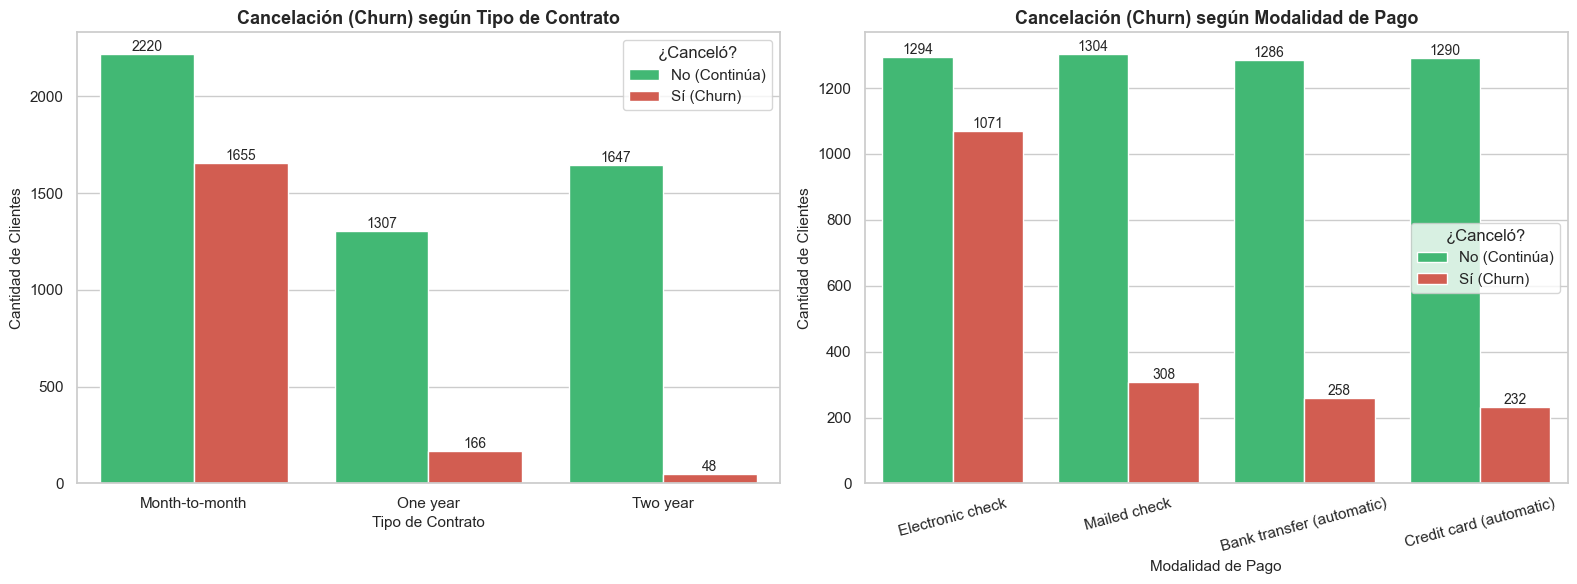

In [58]:
# Configuración estética de Seaborn
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Gráfico 1: Tasa de cancelación según Tipo de Contrato
ax1 = sns.countplot(
    data=df_clean,
    x='Contract',
    hue='Churn',
    palette=['#2ecc71', '#e74c3c'],
    order=['Month-to-month', 'One year', 'Two year'],
    ax=axes[0]
)
axes[0].set_title('Cancelación (Churn) según Tipo de Contrato', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Tipo de Contrato', fontsize=11)
axes[0].set_ylabel('Cantidad de Clientes', fontsize=11)
axes[0].legend(title='¿Canceló?', labels=['No (Continúa)', 'Sí (Churn)'])

for container in ax1.containers:
    ax1.bar_label(container, fontsize=10)

# Gráfico 2: Tasa de cancelación según Modalidad de Pago
ax2 = sns.countplot(
    data=df_clean,
    x='PaymentMethod',
    hue='Churn',
    palette=['#2ecc71', '#e74c3c'],
    ax=axes[1]
)
axes[1].set_title('Cancelación (Churn) según Modalidad de Pago', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Modalidad de Pago', fontsize=11)
axes[1].set_ylabel('Cantidad de Clientes', fontsize=11)
axes[1].tick_params(axis='x', rotation=15)
axes[1].legend(title='¿Canceló?', labels=['No (Continúa)', 'Sí (Churn)'])

for container in ax2.containers:
    ax2.bar_label(container, fontsize=10)

plt.tight_layout()
plt.show()

#### 💡 Interpretación Analítica Orientada al Impacto en el Negocio

1. **Análisis por Tipo de Contrato (`Contract`):**
   * **Hallazgo Estadístico:** Aunque la tasa general de cancelación de la empresa es del **26.54%** (1.869 bajas sobre 7.043 clientes), el abandono está fuertemente concentrado en los contratos mensuales (`Month-to-month`), los cuales representan el **55.02%** de la cartera total y sufren una tasa de cancelación crítica del **42.71%** (1.655 bajas). Por el contrario, en los contratos de 1 año (`One year`) la baja cae al **11.27%**, y en los de 2 años (`Two year`) es de apenas el **2.83%**.
   * **Impacto en el Negocio:** La falta de compromiso contractual a largo plazo es el principal impulsor de pérdida de ingresos recurrentes. Se recomienda diseñar incentivos comerciales (descuentos en el abono mensual o meses bonificados) para migrar a los clientes de modalidad mes a mes hacia contratos anuales.

2. **Análisis por Modalidad de Pago (`PaymentMethod`):**
   * **Hallazgo Estadístico:** Los clientes que abonan mediante cheque electrónico (`Electronic check`, el **33.58%** del total) registran una tasa de abandono sumamente elevada del **45.29%** (1.071 bajas). En contraste, quienes utilizan medios de pago automáticos presentan tasas de fuga casi tres veces menores: **16.71%** en transferencia bancaria automática y **15.24%** en tarjeta de crédito automática.
   * **Impacto en el Negocio:** Los métodos de pago manuales generan fricción mes a mes y exponen al cliente a reconsiderar la continuidad del servicio en cada vencimiento. La estrategia comercial debe enfocarse en bonificar la adhesión al débito automático con tarjeta o cuenta bancaria para fidelizar la cartera.

# ​🅱️​ Parte de Candela - Outliers, Groupby, EDA y Visualizacion


In [59]:
df_clean.shape

(7043, 23)

In [60]:
df_clean["Churn_num"] = (df_clean["Churn"] == "Yes").astype(int)
COLORES = {"No": "#2a78d6", "Yes": "#eb6834"} #azul = se queda, naranja = se va

In [61]:
print(df_clean["TotalCharges"].isna().sum())
print((df_clean["TotalCharges"] == 0).sum())
print(df_clean["Churn_num"].mean().round(3))

0
11
0.265


# Paso 1: Outliers (Tarea JIRA: GIADD-7)

In [63]:
columnas = ["Tenure", "MonthlyCharges", "TotalCharges"]
for col in columnas:
    q1 = df_clean[col].quantile(0.25)
    q3 = df_clean[col].quantile(0.75)
    iqr = q3 - q1
    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr
    outliers = df_clean[(df_clean[col] < limite_inferior) | (df_clean[col] > limite_superior)]

    print(col)
    print("Q1:", round(q1, 2), "| Q3:", round(q3, 2), "| IQR:", round(iqr, 2))
    print("Limites:", round(limite_inferior, 2), "a", round(limite_superior, 2))
    print("Minimo:", df_clean[col].min(), "| Maximo:", df_clean[col].max())
    print("Cantidad de Outliers:", len(outliers))
    print("-" * 40)

Tenure
Q1: 9.0 | Q3: 55.0 | IQR: 46.0
Limites: -60.0 a 124.0
Minimo: 0 | Maximo: 72
Cantidad de Outliers: 0
----------------------------------------
MonthlyCharges
Q1: 35.5 | Q3: 89.85 | IQR: 54.35
Limites: -46.02 a 171.38
Minimo: 18.25 | Maximo: 118.75
Cantidad de Outliers: 0
----------------------------------------
TotalCharges
Q1: 398.55 | Q3: 3786.6 | IQR: 3388.05
Limites: -4683.52 a 8868.67
Minimo: 0.0 | Maximo: 8684.8
Cantidad de Outliers: 0
----------------------------------------


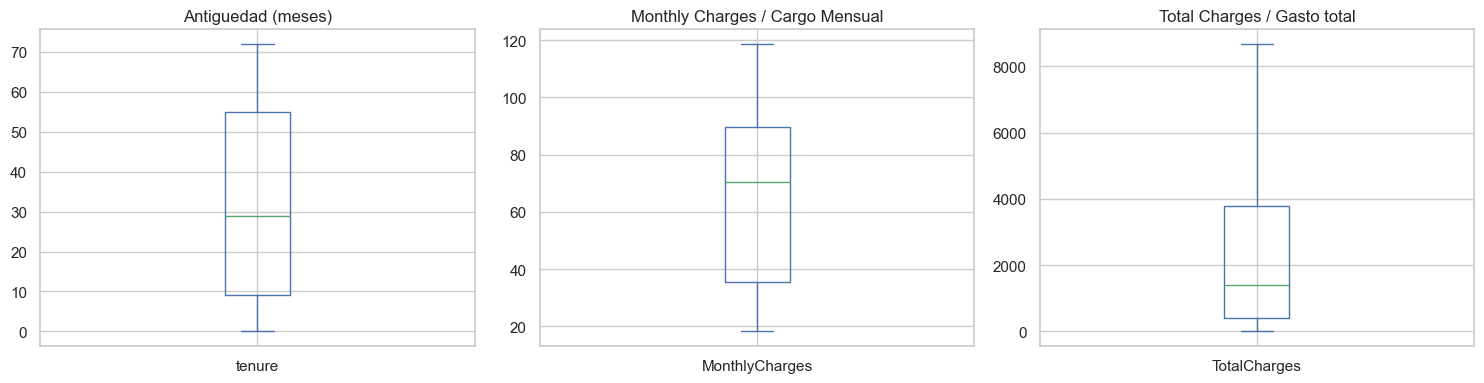

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

df_clean["tenure"].plot(kind="box", ax=axes[0])
axes[0].set_title("Antiguedad (meses)")

df_clean["MonthlyCharges"].plot(kind="box", ax=axes[1])
axes[1].set_title("Monthly Charges / Cargo Mensual")

df_clean["TotalCharges"].plot(kind="box", ax=axes[2])
axes[2].set_title("Total Charges / Gasto total")

plt.tight_layout()
plt.show()

**¿Qué muestra?** La distribucion de tenure, MonthlyCharges y TotalCharges y si hay valores fuera de los bigotes (metodo IQR)

**Dato Concreto** Ninguna de las tres variables tienen outliers. 
- En *tenure* los limtes son [-60: 124] y los datos van de 0 a 72 meses
- En *MonthlyCharges* los limites son [-46,02; 171,38] y los datos van de 18.25 a 118,75
- En *TotalCharges* los limites [-4.6383,52; 8.868,67] y los datos van de 0 a 8.684,80

**Interpretacion:** Los valores altos son los clientes reales (con mucha antiguedad o planes caros), no errores de carga

**Decision de negocio** No se elimina ningun registro; `df_clean` queda como DataFrame final para el resto del analisis

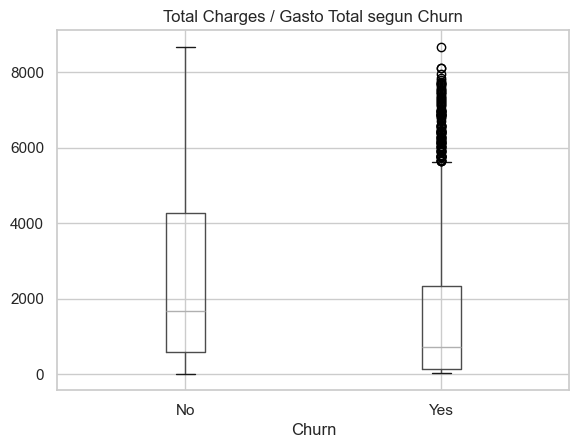

In [ ]:
df_clean.boxplot(column="TotalCharges", by="Churn")
plt.title("Total Charges / Gasto Total segun Churn")
plt.suptitle("")
plt.show()

In [ ]:
churn_si = df_clean[df_clean["Churn"] == "Yes"]

q1 = churn_si["TotalCharges"].quantile(0.25)
q3 = churn_si["TotalCharges"].quantile(0.75)
iqr = q3 - q1
limite_superior = q3 + 1.5 * iqr

altos = churn_si[churn_si["TotalCharges"] > limite_superior]

print("Cantidad de valores altos:", len(altos))
print("Antiguedad promedio:", round(altos["tenure"].mean(), 1 ))
print("Cargo mensual promedio", round(altos["MonthlyCharges"].mean(), 2))
print("-" * 40)
print(altos["InternetService"].value_counts())

Cantidad de valores altos: 109
Antiguedad promedio: 63.9
Cargo mensual promedio 104.15
----------------------------------------
InternetService
Fiber optic    108
DSL              1
Name: count, dtype: int64


In [ ]:
cociente = df_clean["TotalCharges"] / (df_clean["tenure"] * df_clean["MonthlyCharges"])
print("Mediana del cociente", round(cociente.median(), 2))

Mediana del cociente 1.0


**¿Qué muestra?** El gasto total separado entre clientes que se quedan (No) y que se van (Yes)

**Dato Concreto** Dentro de Churn = Yes hay 109 valores altos de TotalCharges; promedian 63,9 meses de antiguedad y 104,15 de cargo mensual, y 108 de ellos tienen `Fiber Optic`. Ademas TotalCharges ≈ tenure × MonthlyCharges (mediana del cociente = 1.00)

**Interpretacion** No son errores: son clientes antiguos con planes caros que igualmente se dieron de baja

**Decision de negocio** Se conservan, por que son los clientes mas valiosos perdidos y es importante estudiarlos y analizarlos (fibra optica con cargo alto). `df_clean` queda como dataFrame final

## Paso 2: Groupby (Tarea JIRA: G1ADD-15)

In [ ]:
por_contrato = df_clean.groupby("Contract").agg({"Churn_num": ["count", "sum", "mean"]})
print(por_contrato.round(3))

               Churn_num             
                   count   sum   mean
Contract                             
Month-to-month      3875  1655  0.427
One year            1473   166  0.113
Two year            1695    48  0.028


In [ ]:
bajas = df_clean.groupby("Contract")["Churn_num"].sum()
print((bajas / bajas.sum() * 100).round(1))

Contract
Month-to-month    88.6
One year           8.9
Two year           2.6
Name: Churn_num, dtype: float64


**¿Qué muestra?** Cantidad de clientes, bajas y tasa de churn según el tipo de contrato

**Dato concreto**
- Month-to-Month: 3.875 clientes, 1.655 bajas -> 42.7% de churn
- One year: 1.473 clientes, 166 bajas -> 11,3% de churn
- Two year: 1.695 clientes, 48 bajas -> 2,8% de churn
- En contrato mes a mes concetra el 88,6% de todas las bajas

**Interpretacion** Cuanto mas largo es el contrato, menos clientes se van. El cliente mes a mes no tiene ningun compromiso que lo retenga

**Decision de negocio** Ofrecer algun incentivo ya sea descuento o beneficio para que los clientes mes a mes pasen a contratos de 1 o 2 años


In [ ]:
por_internet = df_clean.groupby("InternetService").agg({"Churn_num": ["count", "sum", "mean"]})
print(por_internet.round(3))

                Churn_num             
                    count   sum   mean
InternetService                       
DSL                  2421   459  0.190
Fiber optic          3096  1297  0.419
No                   1526   113  0.074


**¿Qué muestra?** La cantidad de clientes, bajas y tasa de churn segun el servicio de internet

**Dato concreto**
- DSL: 2.421 clientes, 459 bajas -> 19,0% de churn
- Fiber optic: 3.096 clientes, 1.297 -> 41,9% de churn
- No/No internet: 1.526 clientes, 113 bajas -> 7.4% de churn

**Interpretacion** La fibra optica, que es el servicio mas caro, tiene mas del doble de churn que DLS. Coincide con lo visto en outliers: 108 de los 109 clientes valiosos que se fueron, tenian Fiber optic.

**Decision de negocio** Revisar el precio y la calidad del servicio de fibra optica, porque es donde se pierden mas clientes

In [ ]:
por_pago = df_clean.groupby("PaymentMethod").agg({"Churn_num": ["count", "sum", "mean"]})
print(por_pago.round(3))

                          Churn_num             
                              count   sum   mean
PaymentMethod                                   
Bank transfer (automatic)      1544   258  0.167
Credit card (automatic)        1522   232  0.152
Electronic check               2365  1071  0.453
Mailed check                   1612   308  0.191


**¿Qué muestra?** La cantidad de clientes, bajas y tasa de churn segun el medio de pago

**Dato concreto**
- Electronic check: 2.365 clientes, 1.071 bajas -> 45,3% de churn
- Mailed check: 19,1%. Back transfer (automatic): 16,7%. Credit card (automatic): 15,2%

**Interpretacion** El cheque electronico casi triplica el churn de los pagos automaticos. Los pagos automaticos (transferencia o tarjeta) hacen que el cliente no tenga que decidir todos los meses si sigue pagando

**Decision de negocio** Incentivar el cambio a pago automatico, por ejemplo con un descuento por adherirse al debito coon tarjeta o banco

## Paso 3: EDA cuantitativo (Tarea JIRA: G1ADD-8)

In [ ]:
columnas = ["tenure", "MonthlyCharges", "TotalCharges"]
print(df_clean[columnas].describe().round(2))

        tenure  MonthlyCharges  TotalCharges
count  7043.00         7043.00       7043.00
mean     32.37           64.76       2279.73
std      24.56           30.09       2266.79
min       0.00           18.25          0.00
25%       9.00           35.50        398.55
50%      29.00           70.35       1394.55
75%      55.00           89.85       3786.60
max      72.00          118.75       8684.80


In [ ]:
for col in columnas:
    print(col)
    print("Media:", round(df_clean[col].mean(), 2))
    print("Mediana:", round(df_clean[col].median(), 2))
    print("Desvio estandar:", round(df_clean[col].std(), 2))
    print("Varianza:", round(df_clean[col].var(), 2))
    print("IQR:", round(df_clean[col].quantile(0.75) - df_clean[col].quantile(0.25), 2))
    print("Asimetria:", round(df_clean[col].skew(), 2))
    print("Curtosis:", round(df_clean[col].kurt(), 2))
    print("-" * 40)

tenure
Media: 32.37
Mediana: 29.0
Desvio estandar: 24.56
Varianza: 603.17
IQR: 46.0
Asimetria: 0.24
Curtosis: -1.39
----------------------------------------
MonthlyCharges
Media: 64.76
Mediana: 70.35
Desvio estandar: 30.09
Varianza: 905.41
IQR: 54.35
Asimetria: -0.22
Curtosis: -1.26
----------------------------------------
TotalCharges
Media: 2279.73
Mediana: 1394.55
Desvio estandar: 2266.79
Varianza: 5138357.17
IQR: 3388.05
Asimetria: 0.96
Curtosis: -0.23
----------------------------------------


In [ ]:
print(df_clean["tenure"].value_counts().head(3))

tenure
1     613
72    362
2     238
Name: count, dtype: int64


**¿Qué muestra?** Medidas de tendencia central, dispersion y forma de tenure, MonthlyCharges y TotalCharges

**Dato concreto**
- Tenure: media 32,37 y mediana 29 meses; moda 1 mes (613 clientes)
- MonthlyCharges: media 64,76 y mediana 70,35; asimetria -0,22
- TotalCharges: media 2.279,73 y mediana 1.394,55; asimetria 0,96 (la mas asimetrica)

- Las tres variables tienen curtosis negativa (distribuciones planas, sin colas pesadas)

**Interpretacion** TotalCharges tiene asimetria positiva: la mayoria de los clientes gastó poco y unos pocos gastaron mucho, por eso la mediana lo representa mejor que la media. La moda de tenure en 1 mes indica que hay muchos clientes recien llegados. La curtosis negativa coincide con lo visto en el Paso 1: no hay outliers

**Decision de negocio** Usar la mediana para describir al cliente típico en gasto total, y prestar atencion a los clientes de los primeros meses, que son un grupo muy numeroso

In [ ]:
cols_corr = ["tenure", "MonthlyCharges", "TotalCharges", "Churn_num"]
pearson = df_clean[cols_corr].corr()
print(pearson.round(2))

                tenure  MonthlyCharges  TotalCharges  Churn_num
tenure            1.00            0.25          0.83      -0.35
MonthlyCharges    0.25            1.00          0.65       0.19
TotalCharges      0.83            0.65          1.00      -0.20
Churn_num        -0.35            0.19         -0.20       1.00


In [ ]:
spearman = df_clean[cols_corr].corr(method="spearman")
print(spearman.round(2))

**¿Qué muestra?** La correlacion de Pearson y de Spearman entre tenure, MonthlyCharges, TotalCharges y Churn

**Dato Concreto** (Pearson P | Spearman S)
- Tenure - TotalCharges: P: 0,83, S: 0,89 -> Relacion fuerte y positiva
- MonthlyCharges - TotalCharges: P: 0,65, S: 0,64
- Tenure - MonthlyCharges: P: 0,25, S: 0,28 -> Relacion debil
- Tenure - Churn: P: -0,35, S: -0,37 -> a mas antiguedad menos bajas
- MonthlyCharges - Churn: P: 0,19, S: 0,18 -> a mayor cargo, algo mas de bajas 

**Interpretacion** La antiguedad es la variable numerica mas relacionada con el churn: los clientes nuevos se van mucho mas. TotalCharges esta muy correlacionada con tenure porque se calcula a partir de ella (meses × cargo mensual). Pearson y Spearman dan resultados parecidos, asi que las conclusiones son solidas

**Decision de negocio** Concentrar las acciones de retencion en los primeros meses del cliente, que es cuando mas riesgo hay de que se vaya

## Paso 4: Visualizacion (Tarea JIRA: G1ADD-17)

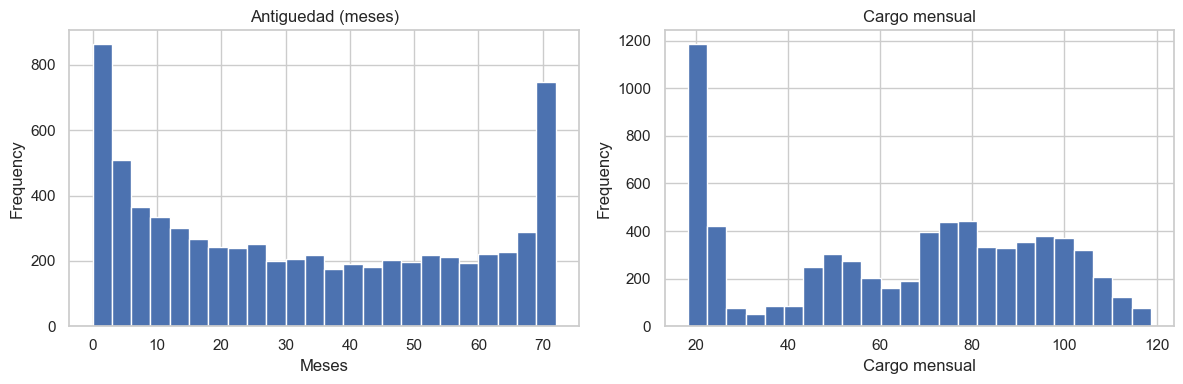

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

df_clean["tenure"].plot(kind="hist", bins=24, ax=axes[0])
axes[0].set_title("Antiguedad (meses)")
axes[0].set_xlabel("Meses")

df_clean["MonthlyCharges"].plot(kind="hist", bins=24, ax=axes[1])
axes[1].set_title("Cargo mensual")
axes[1].set_xlabel("Cargo mensual")

plt.tight_layout()
plt.show()

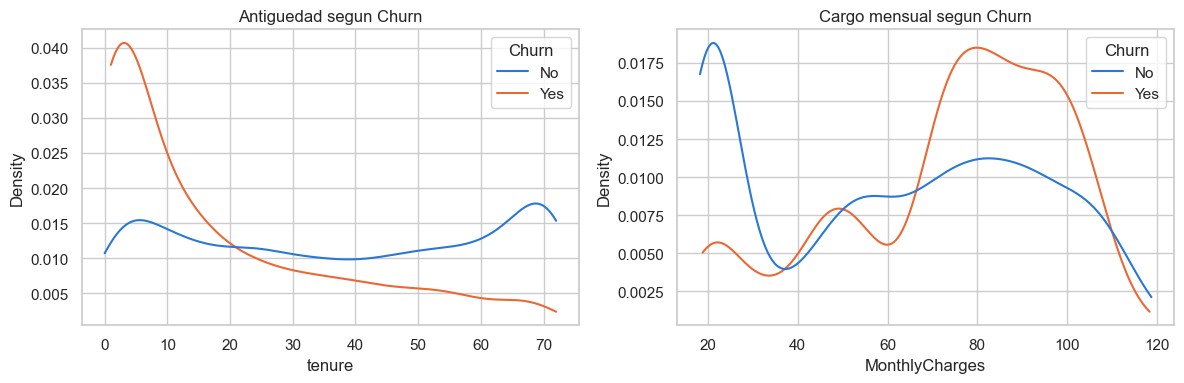

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.kdeplot(data=df_clean, x="tenure", hue="Churn", palette=COLORES, common_norm=False, cut=0, ax=axes[0])
axes[0].set_title("Antiguedad segun Churn")

sns.kdeplot(data=df_clean, x="MonthlyCharges", hue="Churn", palette=COLORES, common_norm=False, cut=0, ax=axes[1])
axes[1].set_title("Cargo mensual segun Churn")

plt.tight_layout()

plt.show()


In [ ]:
nuevos = df_clean[df_clean["tenure"] <= 12]
antiguos = df_clean[df_clean["tenure"] > 48]
print("Churn con 12 meses o menos:", round(nuevos["Churn_num"].mean() * 100, 1), "%")
print("Churn con más de 48 meses:", round(antiguos["Churn_num"].mean() * 100, 1), "%")
print("-" * 40)

baratos = df_clean[df_clean["MonthlyCharges"] < 25]
print("Clientes que pagan menos de 25:", round(len(baratos) / len(df_clean) * 100, 1), "%")

hasta_30 = df_clean[df_clean["MonthlyCharges"] <= 30]
entre_70_90 = df_clean[(df_clean["MonthlyCharges"] > 70) & (df_clean["MonthlyCharges"] <= 90)]
print("Churn con cargo hasta 30:", round(hasta_30["Churn_num"].mean() * 100, 1), "%")
print("Churn con cargo entre 70 y 90:", round(entre_70_90["Churn_num"].mean() * 100, 1), "%")

Churn con 12 meses o menos: 47.4 %
Churn con más de 48 meses: 9.5 %
----------------------------------------
Clientes que pagan menos de 25: 19.7 %
Churn con cargo hasta 30: 9.8 %
Churn con cargo entre 70 y 90: 37.8 %


**¿Qué muestra?** La distribución de tenure y MonthlyCharges: primero en general (histogramas) y después separada entre clientes que se quedan y que se van (KDE).

**Dato concreto:**
- Tenure: el churn es de 47,4% entre los clientes con 12 meses o menos, y de solo 9,5% entre los que llevan más de 48 meses.
- MonthlyCharges: el 19,7% de los clientes paga menos de 25. El churn es de 9,8% con cargos de hasta 30, y de 37,8% con cargos entre 70 y 90.

**Interpretación:** El primer año es el momento de mayor riesgo: casi la mitad de los clientes nuevos se va. Los que pagan poco (servicios básicos, sin internet) casi no se van; en cambio, los cargos medios-altos (donde está la fibra óptica) concentran muchas bajas.

**Decisión de negocio:** Crear un programa de bienvenida y seguimiento para los clientes en su primer año, y revisar la relación precio/servicio de los planes de 70 a 90.


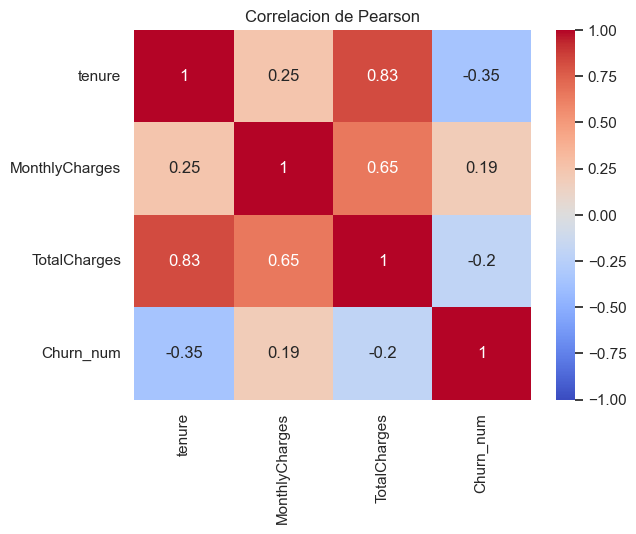

In [ ]:
sns.heatmap(pearson, annot=True, cmap="coolwarm", vmin=-1, vmax=1, center=0)
plt.title("Correlacion de Pearson")
plt.show()

**¿Qué muestra?** La correlación de Pearson entre tenure, MonthlyCharges, TotalCharges y Churn, con colores: rojo para relaciones positivas y azul para negativas.

**Dato concreto:**
- La relación más fuerte es Tenure – TotalCharges (0,83), en rojo intenso.
- La relación más fuerte con el churn es Tenure – Churn (−0,35), en azul.
- MonthlyCharges – Churn (0,19): es positiva pero débil.

**Interpretación:** La antigüedad es el factor numérico que más se asocia a quedarse: a más meses, menos bajas. El cargo mensual alto se asocia a algo más de bajas, pero con menos fuerza. Correlación no implica causalidad.

**Decisión de negocio:** Priorizar la retención temprana (aumentar la antigüedad del cliente) por sobre bajar precios, porque la antigüedad tiene una relación más fuerte con el churn.

# ©️ Preprocesamiento y Modelado Predictivo

In [ ]:
# Llamado al df ya procesado y limpio para uso posterior
df_clean = pd.read_csv("../data/processed/telco_customer_churn_processed.csv").rename(
    columns={"Tenure": "tenure", "Gender": "gender"}
)

# TABLA DE TIPOS DE VARIABLES 🧩🧩

In [ ]:
# Tabla de tipos de Variables

def generar_tabla_variables(dataframe):
    variable_info = []
    
    # Clasificacion y asignacion de tratamientos óptimos basados en el preprocesamiento real
    for col in dataframe.columns:
        unique_vals = dataframe[col].dropna().unique()
        num_unique = len(unique_vals)
        dtype = str(dataframe[col].dtype)
        
        # Definición del tipo de variable y su respectivo tratamiento
        if col in ['tenure', 'MonthlyCharges', 'TotalCharges']:
            var_type = 'Numérica Continua/Discreta'
            tratamiento = 'Escalado (StandardScaler)'
        elif col == 'SeniorCitizen':
            var_type = 'Binaria (Numérica)'
            tratamiento = 'Dejala asi nomas'
        elif col == 'Churn':
            var_type = 'Variable Objetivo'
            tratamiento = 'No se escala ni se codifica como una variable mas'
        elif col in ['gender', 'Partner', 'Dependents', 'PhoneService', 'PaperlessBilling']:
            var_type = 'Binaria (Nominal)'
            tratamiento = 'Ordinal Encoding'
        elif col == 'Contract':
            var_type = 'Categórica Ordinal'
            tratamiento = 'Ordinal Encoding'
        else:
            var_type = 'Categórica Nominal'
            tratamiento = 'One Hot Encoding'
            
        variable_info.append({
            'Variable': col,
            'Tipo de Dato (Python)': dtype,
            'Tipo de Variable': var_type,
            'Valores Únicos': num_unique,
            'Ejemplos de Valores': list(unique_vals[:3]),
            'Tratamiento Real': tratamiento  
        })
        
    return pd.DataFrame(variable_info)

tabla_variables = generar_tabla_variables(df_clean)
tabla_variables

,Variable,Tipo de Dato (Python),Tipo de Variable,Valores Únicos,Ejemplos de Valores,Tratamiento Real
0,gender,object,Binaria (Nominal),2,"[Female, Male]",Ordinal Encoding
1,SeniorCitizen,int64,Binaria (Numérica),2,"[0, 1]",Dejala asi nomas
2,Partner,object,Binaria (Nominal),2,"[Yes, No]",Ordinal Encoding
3,Dependents,object,Binaria (Nominal),2,"[No, Yes]",Ordinal Encoding
4,tenure,int64,Numérica Continua/Discreta,73,"[1, 34, 2]",Escalado (StandardScaler)
5,PhoneService,object,Binaria (Nominal),2,"[No, Yes]",Ordinal Encoding
6,MultipleLines,object,Categórica Nominal,3,"[No phone service, No, Yes]",One Hot Encoding
7,InternetService,object,Categórica Nominal,3,"[DSL, Fiber optic, No]",One Hot Encoding
8,OnlineSecurity,object,Categórica Nominal,3,"[No, Yes, No internet service]",One Hot Encoding
9,OnlineBackup,object,Categórica Nominal,3,"[Yes, No, No internet service]",One Hot Encoding


# Preprocesamiento de Datos para Modelado 🛠️

In [ ]:
# Definicion de que columnas tendra cada tratamiento
columnas_numericas = ['tenure', 'MonthlyCharges', 'TotalCharges', 'AvgMonthlyCharge', 'ChargeDiff', 'NumServices']
columnas_binarias = ['gender', 'Partner', 'Dependents', 'PhoneService', 'PaperlessBilling']
columnas_ordinales = ['Contract']
columnas_nominales = ['MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 
                'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'PaymentMethod']

# Definicion del orden de contrato (0-2) de menor a mayor
ordenCorrecto_contrato = ['Month-to-month', 'One year', 'Two year']


# Preprocesador utilizando ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), columnas_numericas),
        ('bin_ord', OrdinalEncoder(), columnas_binarias),
        ('contract_ord', OrdinalEncoder(categories=[ordenCorrecto_contrato]), columnas_ordinales),
        ('nom_ohe', OneHotEncoder(drop='first', handle_unknown='ignore', sparse_output=False), columnas_nominales)
    ],
    remainder='passthrough' # Para SeniorCitizen sin cambios es 0 y 1 XD
)

# Variables independientes (X) y variable objetivo (y)
X = df_clean.drop(columns=['Churn'])
y = LabelEncoder().fit_transform(df_clean['Churn'])

# Divicion entre Train y Test antes de transformar
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Ajuste del preprocesador con los datos de entrenamiento y transforme de ambos
X_train_prepared = preprocessor.fit_transform(X_train)
X_test_prepared = preprocessor.transform(X_test)

# Convercion a DataFrame
encoded_cols = preprocessor.get_feature_names_out()

X_train_df = pd.DataFrame(X_train_prepared, columns=encoded_cols)
display(X_train_df.head())

,num__tenure,num__MonthlyCharges,num__TotalCharges,num__AvgMonthlyCharge,num__ChargeDiff,num__NumServices,bin_ord__gender,bin_ord__Partner,bin_ord__Dependents,bin_ord__PhoneService,...,nom_ohe__TechSupport_No internet service,nom_ohe__TechSupport_Yes,nom_ohe__StreamingTV_No internet service,nom_ohe__StreamingTV_Yes,nom_ohe__StreamingMovies_No internet service,nom_ohe__StreamingMovies_Yes,nom_ohe__PaymentMethod_Credit card (automatic),nom_ohe__PaymentMethod_Electronic check,nom_ohe__PaymentMethod_Mailed check,remainder__SeniorCitizen
0,0.102371,-0.521976,-0.262257,-0.539937,0.226348,-0.072199,1.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0
1,-0.711743,0.337478,-0.503635,0.391497,-0.639593,-0.503095,1.0,1.0,1.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2,-0.793155,-0.809013,-0.749883,-0.646151,-1.867305,-0.072199,1.0,1.0,1.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
3,-0.263980,0.284384,-0.172722,0.276681,0.080100,0.789595,0.0,1.0,0.0,1.0,...,0.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,0.0
4,-1.281624,-0.676279,-0.989374,-0.674606,0.003128,-0.933992,1.0,1.0,1.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0


# VERIFICACION DE RESULTADOS 📎

In [ ]:
prep_df = pd.DataFrame(X_train_prepared, columns=preprocessor.get_feature_names_out())

print('1. ¿Todo numérico?              ', prep_df.dtypes.nunique() == 1 and prep_df.dtypes.iloc[0] == 'float64')
print('2. Valores nulos:               ', int(np.isnan(X_train_prepared).sum()))
print('3. ¿Mismas columnas train/test? ', X_train_prepared.shape[1] == X_test_prepared.shape[1])
print('4. Proporción y_train:          ', pd.Series(y_train).value_counts(normalize=True).round(3).to_dict())
print('   Proporción y_test:           ', pd.Series(y_test).value_counts(normalize=True).round(3).to_dict())
cantidad_numericas = len(columnas_numericas)
print('5. Numéricas de train → media:  ', X_train_prepared[:, :cantidad_numericas].mean(axis=0).round(2),
      ' desvío:', X_train_prepared[:, :cantidad_numericas].std(axis=0).round(2))

1. ¿Todo numérico?               True
2. Valores nulos:                0
3. ¿Mismas columnas train/test?  True
4. Proporción y_train:           {0: 0.735, 1: 0.265}
   Proporción y_test:            {0: 0.735, 1: 0.265}
5. Numéricas de train → media:   [-0. -0. -0.  0. -0. -0.]  desvío: [1. 1. 1. 1. 1. 1.]


# **Predicción Numérica: Modelos de Regresión**📈📉

In [ ]:
# Inicializacion del modelo
modelo = LinearRegression()

# Entrenamiento para estimar SOLO una variable continua (TotalCharges)

# Serea comparada con tenure (meses)
X_s = df_clean[['tenure']]
y_s = df_clean['TotalCharges']

# 2. División en conjuntos de entrenamiento y prueba (80/20)
X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(
    X_s, y_s, test_size=0.2, random_state=42
)

# Entrenamiento del modelo utilizando los datos preparados
modelo.fit(X_train_s, y_train_s)

# Consulta de datos aprendidos
# Por cada mes adicional que un cliente permanece en la empresa, sus cargos totales acumulados aumentan $76.59
print("Pendiente del primer coeficiente:", modelo.coef_[0])
print("Intercepto:", modelo.intercept_)

# Prediccion utilizando los datos de test preparados
predicciones = modelo.predict(X_test_s)
print("Predicciones (primeras 5):", predicciones[:5])

# Comparacion con respecto a los datos originales
comparacion = pd.DataFrame({
    'Valor Real': y_test_s,
    'Prediccion': predicciones
})

comparacion = comparacion.head(10)

# Para un cliente con 1 mes de servicio (Fila 185): Su cargo real fue de $24.80, pero el modelo predijo -$113.43. Para clientes nuevos el modelo simple no es tan exacto
# Para un cliente con 41 meses de servicio (Fila 2715): Su cargo real fue de $996.45 y el modelo predijo $2,950.34.
display(comparacion.sort_values('Prediccion'))

Pendiente del primer coeficiente: 76.72873262004292
Intercepto: -196.85836751324587
Predicciones (primeras 5): [-120.12963489 2949.01966991 3793.03572873 -120.12963489 4943.96671803]


,Valor Real,Prediccion
185,24.80,-120.129635
1807,76.35,-120.129635
2526,19.40,-120.129635
3732,1759.40,1567.902483
2715,996.45,2949.019670
3825,1031.70,3793.035729
132,3260.10,4943.966718
1263,6127.60,5020.695451
811,7250.15,5174.152916
1672,5016.65,5327.610381


# Evaluaciones simples 📋

In [ ]:
# MAE: Error absoluto Medio
mae = mean_absolute_error(y_test_s, predicciones)
print("Error Absoluto Medio (MAE):", mae) # -> Se equivoca $892.0415772496411 en promedio

# MSE: Error cuadrático medio
mse = mean_squared_error(y_test_s, predicciones)
print("Error Cuadrático Medio (MSE):", mse) # -> 1717993.9247736863 La empresa ya puede ir pensado en cerrar XD

# R**2: Coeficiente de determinacion
r2 = r2_score(y_test_s, predicciones)
print("Coeficiente de Determinación (R**2):", r2) # -> 0.6695741445638115

metricas = pd.DataFrame({
    "Métrica": ["MAE", "MSE", "R²"],
    "Resultado": [mae, mse, r2]
})

display(metricas)


Error Absoluto Medio (MAE): 892.3789405593451
Error Cuadrático Medio (MSE): 1716419.4491208133
Coeficiente de Determinación (R**2): 0.6700723339739993


,Métrica,Resultado
0,MAE,8.923789e+02
1,MSE,1.716419e+06
2,R²,6.700723e-01


# VISUALIZACION DE LOS RESULTADOS FINALES 📊

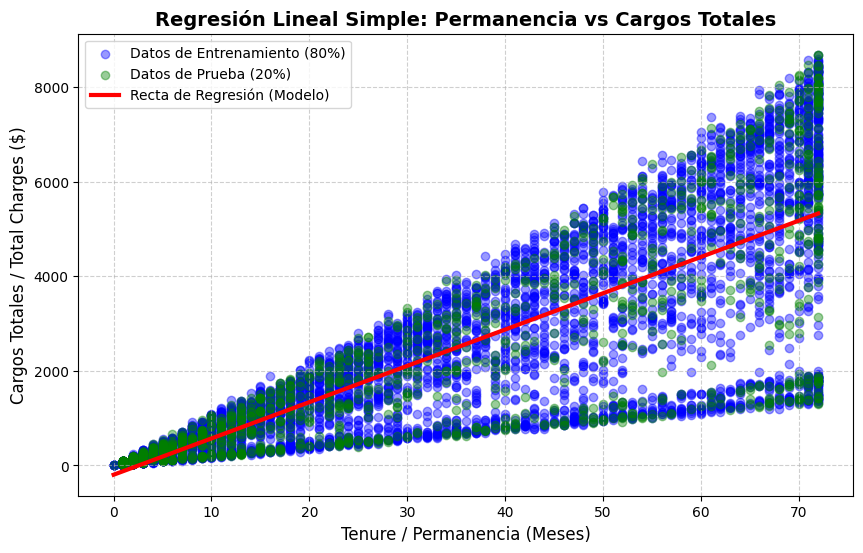

In [ ]:
plt.figure(figsize=(10, 6))

# Datos reales de entrenamiento (en azul)
plt.scatter(
    X_train_s, y_train_s, color='blue', label='Datos de Entrenamiento (80%)', alpha=0.4
)

# Datos reales de prueba reservados (en verde)
plt.scatter(
    X_test_s, y_test_s, color='green', label='Datos de Prueba (20%)', alpha=0.4
)

# Recta de regresión aprendida por el modelo
 # La linea de regresion estaba cortada en partes, esta fue la mejor solucion
X_valores_ordenados = pd.DataFrame(np.sort(X_s.values, axis=0), columns=X_s.columns)
predicciones_ordenadas = modelo.predict(X_valores_ordenados)
plt.plot(
    X_valores_ordenados, predicciones_ordenadas, color='red', linewidth=3, label='Recta de Regresión (Modelo)'
)

# Configuración de etiquetas y títulos correctos
plt.xlabel("Tenure / Permanencia (Meses)", fontsize=12)
plt.ylabel("Cargos Totales / Total Charges ($)", fontsize=12)
plt.title("Regresión Lineal Simple: Permanencia vs Cargos Totales", fontsize=14, fontweight='bold')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

In [ ]:
# FUTURAS PREDICCIONES

# DataFrame con los meses de permanencia
nuevo_cliente = pd.DataFrame({
    'tenure': [24] # Ejemplo: Estimar cargos para un cliente con 2 años de servicio
})

# predicciOn con EL modelo entrenado
cargos_estimados = modelo.predict(nuevo_cliente)

print("--- Predicción Individual ---")
print(f"Permanencia ingresada: {nuevo_cliente['tenure'][0]} meses")
print(f"Cargos Totales estimados: USD {cargos_estimados[0]:,.2f}\n")

# predicciones mUltiples
varios_clientes = pd.DataFrame({
    'tenure': [1, 12, 36, 72] # 1 mes, 1 año, 3 años y 6 años
})

varios_clientes['Cargos Totales Estimados'] = modelo.predict(varios_clientes)
display(varios_clientes)

--- Predicción Individual ---
Permanencia ingresada: 24 meses
Cargos Totales estimados: USD 1,644.63



,tenure,Cargos Totales Estimados
0,1,-120.129635
1,12,723.886424
2,36,2565.376007
3,72,5327.610381
